In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix,classification_report,recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from joblib import dump

In [4]:
df = pd.read_csv("../Datasets/heart_disease_risk_dataset_earlymed.csv")
df.head()

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,48.0,0.0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,46.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,66.0,0.0
3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,60.0,1.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,69.0,0.0


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Chest_Pain           70000 non-null  float64
 1   Shortness_of_Breath  70000 non-null  float64
 2   Fatigue              70000 non-null  float64
 3   Palpitations         70000 non-null  float64
 4   Dizziness            70000 non-null  float64
 5   Swelling             70000 non-null  float64
 6   Pain_Arms_Jaw_Back   70000 non-null  float64
 7   Cold_Sweats_Nausea   70000 non-null  float64
 8   High_BP              70000 non-null  float64
 9   High_Cholesterol     70000 non-null  float64
 10  Diabetes             70000 non-null  float64
 11  Smoking              70000 non-null  float64
 12  Obesity              70000 non-null  float64
 13  Sedentary_Lifestyle  70000 non-null  float64
 14  Family_History       70000 non-null  float64
 15  Chronic_Stress       70000 non-null 

In [32]:
df.isna().sum()

Chest_Pain             0
Shortness_of_Breath    0
Fatigue                0
Palpitations           0
Dizziness              0
Swelling               0
Pain_Arms_Jaw_Back     0
Cold_Sweats_Nausea     0
High_BP                0
High_Cholesterol       0
Diabetes               0
Smoking                0
Obesity                0
Sedentary_Lifestyle    0
Family_History         0
Chronic_Stress         0
Gender                 0
Age                    0
Heart_Risk             0
dtype: int64

In [33]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)


In [34]:
df.reset_index(inplace=True)
df.drop("index",axis=1,inplace=True)
df

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,48.0,0.0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,46.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,66.0,0.0
3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,60.0,1.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,69.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63750,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,0.0
63751,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,30.0,0.0
63752,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,53.0,0.0
63753,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,57.0,1.0


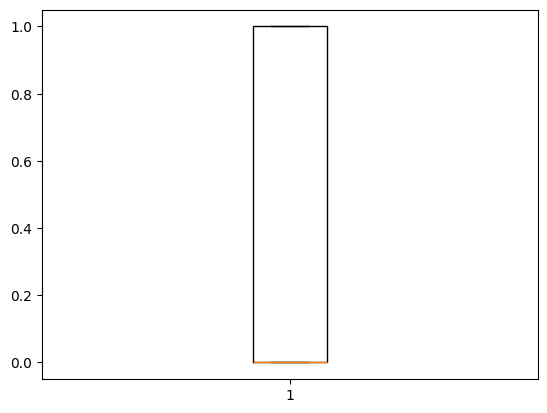

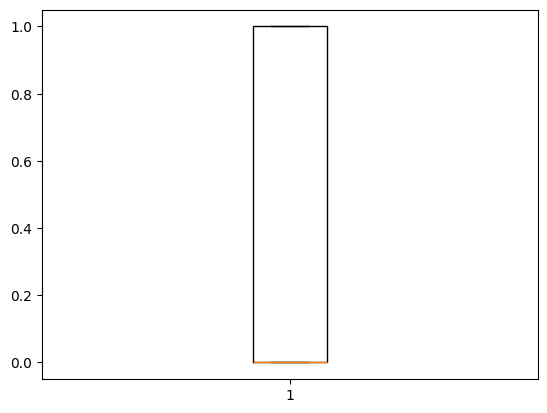

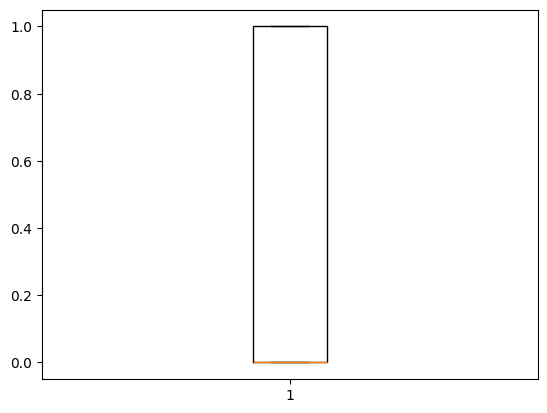

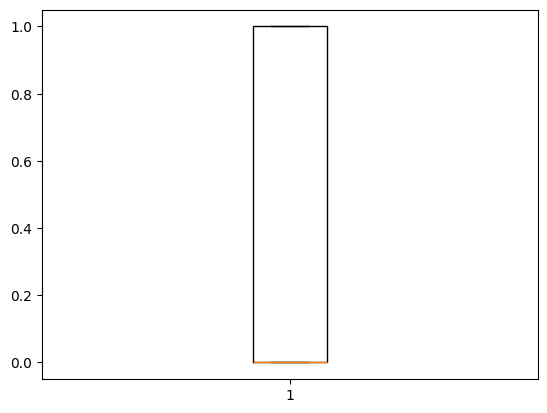

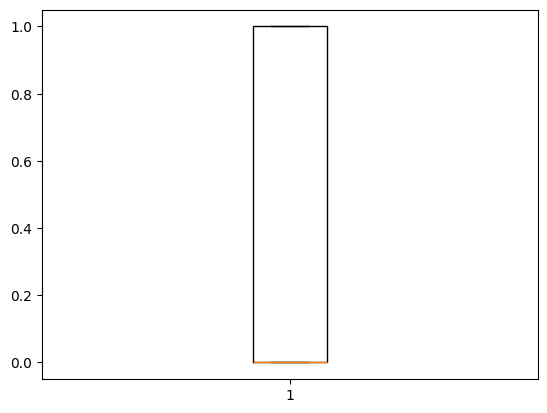

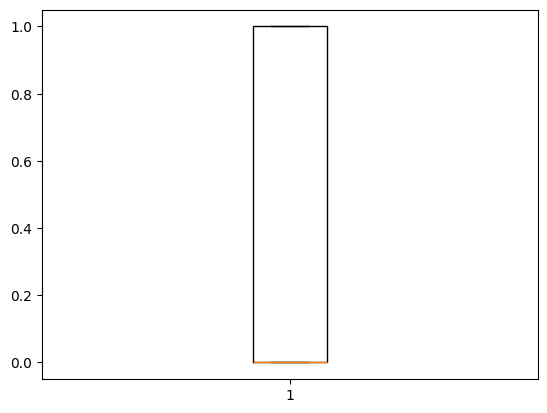

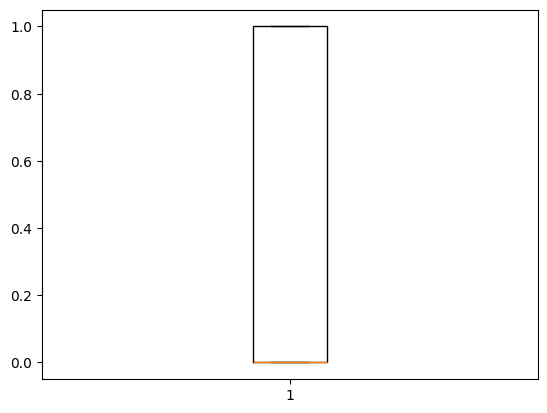

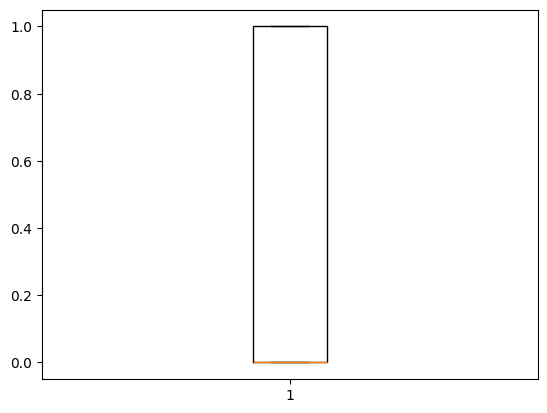

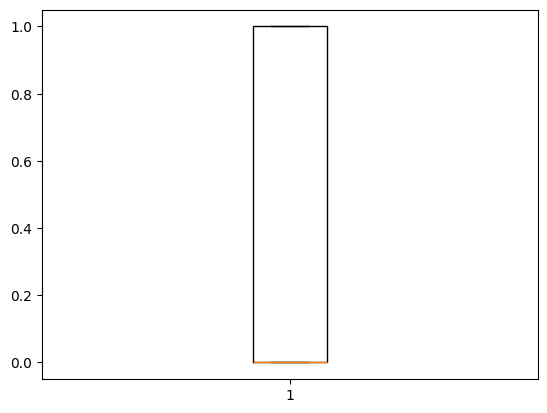

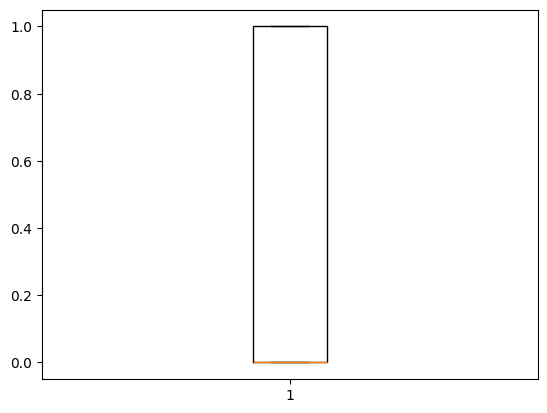

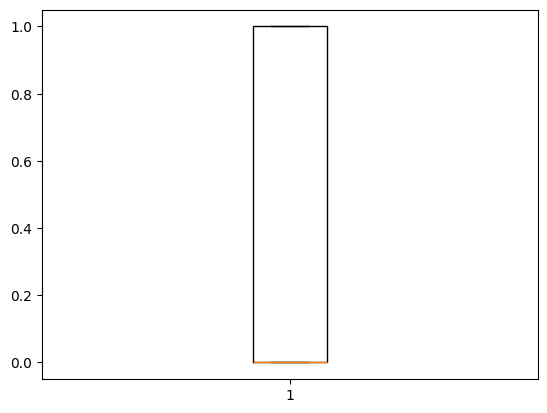

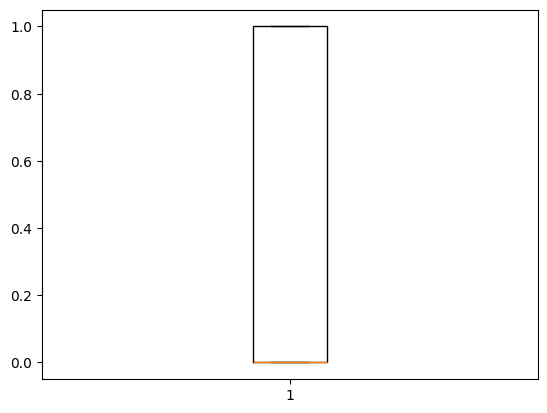

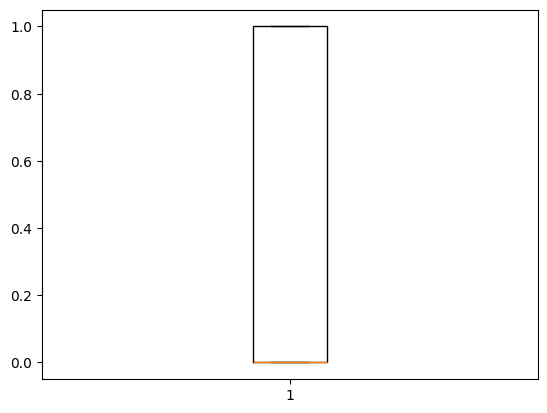

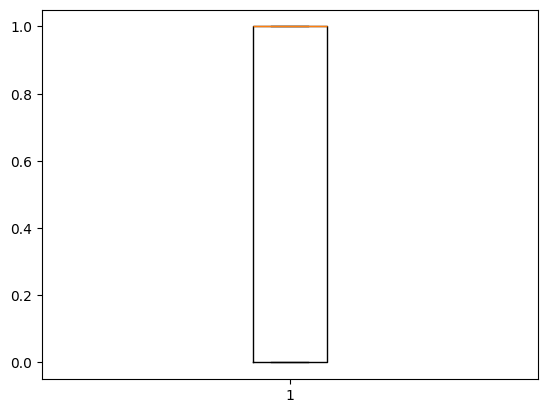

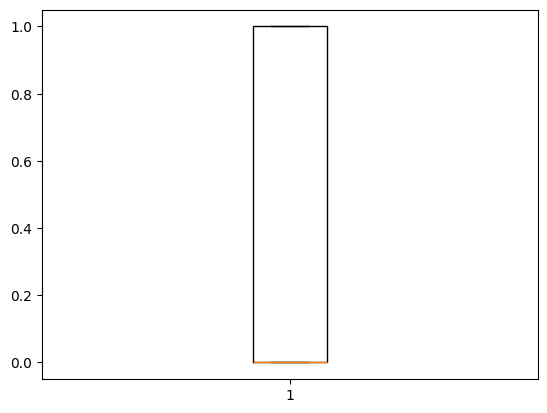

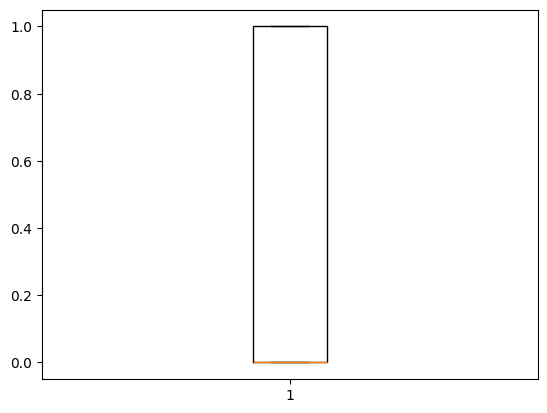

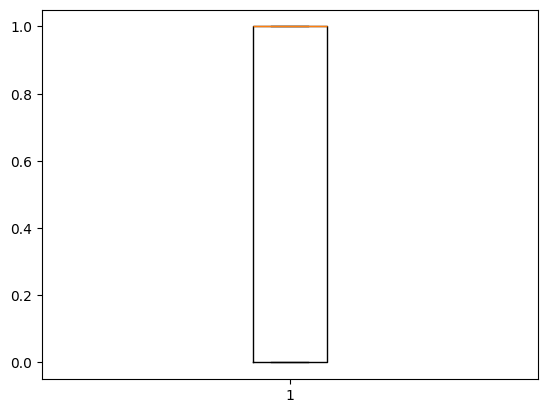

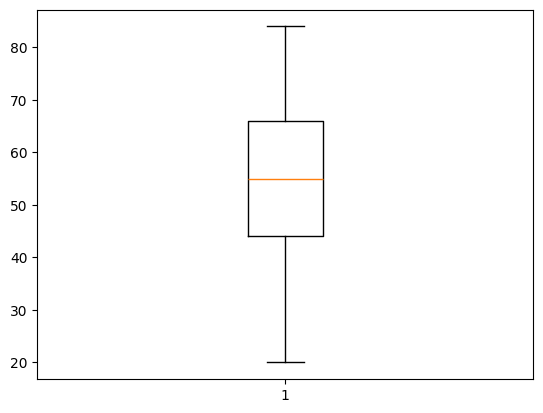

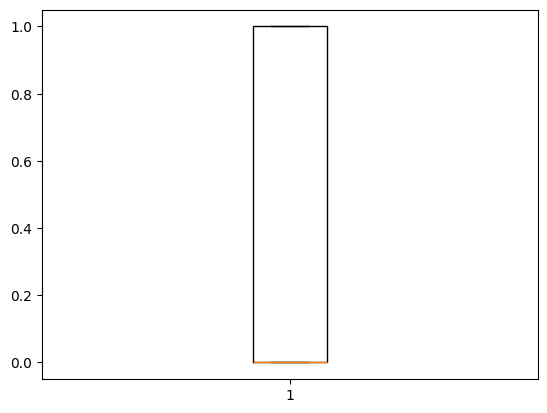

In [35]:
for col in df.columns:
    plt.boxplot(df[col])
    plt.show()

In [36]:
df.corr()["Heart_Risk"].sort_values()

Gender                 0.274181
Diabetes               0.374800
Smoking                0.374995
Family_History         0.375107
Obesity                0.376551
Chronic_Stress         0.376581
High_Cholesterol       0.380875
High_BP                0.380922
Sedentary_Lifestyle    0.382615
Palpitations           0.572232
Shortness_of_Breath    0.572722
Swelling               0.573772
Dizziness              0.575069
Chest_Pain             0.575342
Fatigue                0.575590
Pain_Arms_Jaw_Back     0.576289
Cold_Sweats_Nausea     0.576370
Age                    0.604912
Heart_Risk             1.000000
Name: Heart_Risk, dtype: float64

In [5]:
X = df.drop("Heart_Risk",axis=1)
y = df["Heart_Risk"]
(y.value_counts() / len(df) ) * 100

Heart_Risk
0.0    50.0
1.0    50.0
Name: count, dtype: float64

In [6]:
X_train,X_test,y_trian,y_test = train_test_split(X,y,random_state=12,stratify=y,test_size=0.2)

In [39]:
tree = DecisionTreeClassifier()


In [40]:
tree.fit(X_train,y_trian)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [41]:
tree_test = tree.predict(X_test)
tree_train = tree.predict(X_train)

In [42]:
print(recall_score(y_test,tree_test))
print(recall_score(y_trian,tree_train))

0.9817373352390028
1.0


In [43]:
knn = KNeighborsClassifier(n_neighbors=9)
knn.fit(X_train,y_trian)

,n_neighbors,9
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [44]:
knn_test = knn.predict(X_test)
knn_trian = knn.predict(X_train)

In [45]:
print(recall_score(y_test,knn_test))
print(recall_score(y_trian,knn_trian))

0.9903128473876449
0.9936085748312823


In [46]:
logistic = LogisticRegression()
logistic.fit(X_train,y_trian)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [47]:
logi_test = logistic.predict(X_test)
logi_trian = logistic.predict(X_train)

In [48]:
print(recall_score(y_test,logi_test))
print(recall_score(y_trian,logi_trian))

0.9907892647292361
0.990909090909091


In [49]:
rf = RandomForestClassifier(n_estimators=200,min_samples_split=5)
rf.fit(X_train,y_trian)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [50]:
rf_test = rf.predict(X_test)
rf_train = rf.predict(X_train)

print(recall_score(y_test,rf_test))
print(recall_score(y_trian,rf_train))

0.9903128473876449
0.9976578007145692


In [51]:
xgb = XGBClassifier()


In [52]:
xgb.fit(X_train,y_trian)
xgb_test = xgb.predict(X_test)
xgb_train = xgb.predict(X_train)

In [53]:
print(recall_score(y_test,xgb_test))
print(recall_score(y_trian,xgb_train))

0.9904716531681753
0.9998809051210797


In [54]:
X_train.head(3)

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age
48086,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,35.0
21176,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,53.0
59486,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,59.0


In [55]:
dump(logistic,"Heart_model.joblib")

['Heart_model.joblib']

In [67]:
new_data =np.array([[1,	1,	1,	1,	1,	0,	1,0,0,1,0,1,	0,	0,	1,	1,	0,	42]])

In [68]:
logistic.predict(new_data)

c:\Users\kripank\Desktop\fast API\env\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1.])

In [7]:
print(X_train.columns.tolist())

['Chest_Pain', 'Shortness_of_Breath', 'Fatigue', 'Palpitations', 'Dizziness', 'Swelling', 'Pain_Arms_Jaw_Back', 'Cold_Sweats_Nausea', 'High_BP', 'High_Cholesterol', 'Diabetes', 'Smoking', 'Obesity', 'Sedentary_Lifestyle', 'Family_History', 'Chronic_Stress', 'Gender', 'Age']
